mass 1: r = [1. 0. 1.] m, |r| = 1.4142 m
        phi = 45.0 deg, rho = 1.0 m
        v = omega x r = [0. 2. 0.] m/s, |v| = 2.0 m/s
        rho*omega = 2.0 m/s
        v.r = 0.0 , v.omega = 0.0
mass 2: v = [ 0. -2.  0.] m/s
saved the figure


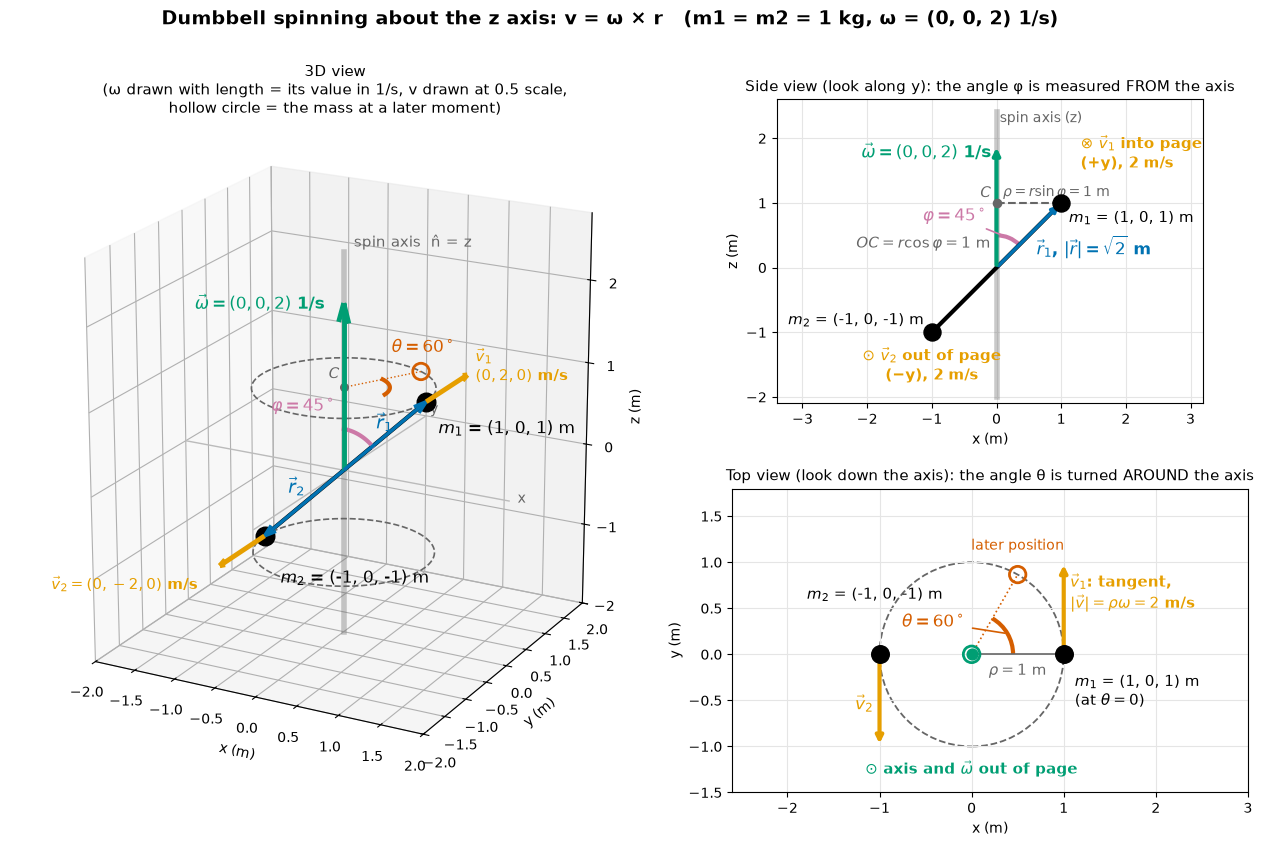

In [2]:
import os
from datetime import datetime

import numpy as np  # type: ignore
import matplotlib.pyplot as plt  # type: ignore
from matplotlib.patches import Arc, Circle  # type: ignore

RESULT_DIR = os.path.join(os.getcwd(), "result")
os.makedirs(RESULT_DIR, exist_ok=True)
TIMESTAMP = datetime.now().strftime("%Y%m%d_%H%M%S")

# colors (Okabe-Ito, colorblind safe)
C_R = "#0072B2"      # position arrow r
C_V = "#E69F00"      # tangential velocity v
C_W = "#009E73"      # angular velocity omega
C_PHI = "#CC79A7"    # angle phi (from the axis)
C_THETA = "#D55E00"  # angle theta (around the axis)
C_GRAY = "#666666"
C_LIGHT = "#BBBBBB"
C_BLACK = "black"    # mass names and their coordinates

# =============================================================================
# STEP 1: Inputs (the dumbbell problem)
# What we have:  two masses of 1 kg at P1 = (1,0,1) m and P2 = -P1,
#                spin axis = z, angular velocity vector omega = (0,0,2) 1/s
# What we want:  the numbers and angles we will draw
# Why:           everything below is computed from these few inputs
# Formula:       omega_vec = omega * n_hat
# =============================================================================
MASS = 1.0                                 # kg
P1 = np.array([1.0, 0.0, 1.0])             # m
P2 = -P1                                   # m
N_HAT = np.array([0.0, 0.0, 1.0])          # unit arrow along the axis
OMEGA = 2.0                                # 1/s
OMEGA_VEC = OMEGA * N_HAT                  # 1/s
THETA_SHOW = np.deg2rad(60.0)              # rad, a later moment, only for drawing theta
V_SCALE = 0.5                              # v arrows are drawn at this scale (m/s -> plot units)


def coord_str(p):
    """'(x, y, z) m' text for a position; the + 0.0 turns -0.0 into 0."""
    return "(" + ", ".join(f"{c + 0.0:g}" for c in p) + ") m"


M1_TXT = r"$m_1$ = " + coord_str(P1)       # m1 name and coordinates
M2_TXT = r"$m_2$ = " + coord_str(P2)       # m2 name and coordinates

# =============================================================================
# STEP 2: Geometry of mass 1 (and mass 2)
# What we have:  r (from O to the mass), the axis n_hat
# What we want:  phi (angle FROM the axis), rho (distance from the axis),
#                the center C of the circle the mass traces
# Why:           phi sets the size of v, theta (later) moves the mass around the circle
# Formulas:      cos(phi) = (r . n_hat) / |r|
#                r_par = (r . n_hat) n_hat            (along the axis)
#                r_perp = r - r_par,  rho = |r_perp|  (across the axis) = |r| sin(phi)
#                C = r_par
# =============================================================================
def geometry(r):
    r_norm = np.linalg.norm(r)
    phi = np.arccos((r @ N_HAT) / r_norm)
    r_par = (r @ N_HAT) * N_HAT
    r_perp = r - r_par
    rho = np.linalg.norm(r_perp)
    e1 = r_perp / rho                     # unit arrow from C toward the mass at theta = 0
    e2 = np.cross(N_HAT, e1)              # unit arrow, a quarter turn ahead
    return r_norm, phi, rho, r_par, e1, e2


r1_norm, phi1, rho1, C1, e1_1, e2_1 = geometry(P1)
r2_norm, phi2, rho2, C2, e1_2, e2_2 = geometry(P2)

# =============================================================================
# STEP 3: Tangential velocity of each mass
# What we have:  omega_vec and r
# What we want:  v for each mass
# Why:           this is the result we proved: v = omega x r
# Formulas:      v = omega_vec x r
#                |v| = rho * omega = omega * |r| * sin(phi)
#                v . r = 0 and v . omega_vec = 0
# =============================================================================
v1 = np.cross(OMEGA_VEC, P1)
v2 = np.cross(OMEGA_VEC, P2)

print("mass 1: r =", P1, "m, |r| =", round(r1_norm, 4), "m")
print("        phi =", round(np.degrees(phi1), 2), "deg, rho =", round(rho1, 4), "m")
print("        v = omega x r =", v1, "m/s, |v| =", round(np.linalg.norm(v1), 4), "m/s")
print("        rho*omega =", round(rho1 * OMEGA, 4), "m/s")
print("        v.r =", v1 @ P1, ", v.omega =", v1 @ OMEGA_VEC)
print("mass 2: v =", v2, "m/s")

# =============================================================================
# STEP 4: Figure layout
# What we have:  all the numbers above
# What we want:  3D view (left), side view (top right), top view (bottom right)
# Why:           3D shows the whole picture, the 2D views show phi and theta cleanly
# =============================================================================
fig = plt.figure(figsize=(16, 9))
gs = fig.add_gridspec(2, 2, width_ratios=[1.25, 1.0], hspace=0.28, wspace=0.12)
ax3 = fig.add_subplot(gs[:, 0], projection="3d")
ax_side = fig.add_subplot(gs[0, 1])
ax_top = fig.add_subplot(gs[1, 1])
fig.suptitle(
    "Dumbbell spinning about the z axis: v = ω × r   "
    "(m1 = m2 = 1 kg, ω = (0, 0, 2) 1/s)",
    fontsize=14, fontweight="bold",
)

# =============================================================================
# STEP 5: 3D view
# What we have:  P1, P2, axis, circles, v arrows
# What we want:  one picture with the axis, r, v, omega, phi and theta
# Why:           see all the variables in the same space
# =============================================================================
def arrow3d(ax, start, vec, color, lw=2.5, ratio=0.12):
    ax.quiver(start[0], start[1], start[2], vec[0], vec[1], vec[2],
              color=color, linewidth=lw, arrow_length_ratio=ratio)


def circle3d(center, e1, e2, rho, n=200):
    t = np.linspace(0, 2 * np.pi, n)
    pts = center[None, :] + rho * (np.cos(t)[:, None] * e1[None, :] + np.sin(t)[:, None] * e2[None, :])
    return pts


# coordinate lines
ax3.plot([-2, 2], [0, 0], [0, 0], color=C_LIGHT, lw=1)
ax3.plot([0, 0], [-2, 2], [0, 0], color=C_LIGHT, lw=1)
ax3.text(2.1, 0, 0, "x", color=C_GRAY)
ax3.text(0, 2.1, 0, "y", color=C_GRAY)
# the spin axis
ax3.plot([0, 0], [0, 0], [-2.0, 2.6], color=C_GRAY, lw=4, alpha=0.35)
ax3.text(0.08, 0.08, 2.65, "spin axis  n̂ = z", color=C_GRAY, fontsize=11)
# omega arrow (length = value of omega, in 1/s, not meters)
arrow3d(ax3, np.zeros(3), OMEGA_VEC, C_W, lw=3.5)
ax3.text(-0.15, -0.15, 1.95, r"$\vec\omega=(0,0,2)$ 1/s", color=C_W, fontsize=12,
         fontweight="bold", ha="right")
# the rod and masses
ax3.plot([P1[0], P2[0]], [P1[1], P2[1]], [P1[2], P2[2]], color="black", lw=3)
ax3.scatter(*P1, s=180, color="black", zorder=5)
ax3.scatter(*P2, s=180, color="black", zorder=5)
ax3.text(P1[0] + 0.15, P1[1], P1[2] - 0.35, M1_TXT, fontsize=12, color=C_BLACK)
ax3.text(P2[0] + 0.2, P2[1], P2[2] - 0.55, M2_TXT, fontsize=12, color=C_BLACK, ha="left")
# circles traced by each mass
for C, e1, e2, rho in ((C1, e1_1, e2_1, rho1), (C2, e1_2, e2_2, rho2)):
    pts = circle3d(C, e1, e2, rho)
    ax3.plot(pts[:, 0], pts[:, 1], pts[:, 2], color=C_GRAY, lw=1.2, ls="--")
ax3.scatter(*C1, s=30, color=C_GRAY)
ax3.text(C1[0] - 0.12, C1[1] - 0.12, C1[2] + 0.12, r"$C$", color=C_GRAY, fontsize=11)
# r arrows
arrow3d(ax3, np.zeros(3), P1, C_R)
arrow3d(ax3, np.zeros(3), P2, C_R)
ax3.text(0.45, -0.1, 0.62, r"$\vec r_1$", color=C_R, fontsize=13, fontweight="bold")
ax3.text(-0.75, 0.1, -0.45, r"$\vec r_2$", color=C_R, fontsize=13, fontweight="bold")
# v arrows (drawn at scale V_SCALE)
arrow3d(ax3, P1, V_SCALE * v1, C_V, lw=3.5)
arrow3d(ax3, P2, V_SCALE * v2, C_V, lw=3.5)
ax3.text(P1[0] + 0.1, P1[1] + V_SCALE * v1[1], P1[2] - 0.05,
         r"$\vec v_1$" + "\n" + r"$(0,2,0)$ m/s", color=C_V, fontsize=11, fontweight="bold", ha="left")
ax3.text(P2[0] - 0.1, P2[1] + V_SCALE * v2[1] - 0.3, P2[2] - 0.2,
         r"$\vec v_2=(0,-2,0)$ m/s", color=C_V, fontsize=11, fontweight="bold", ha="right")
# phi arc: from the axis toward r1, at the origin
s = np.linspace(0, phi1, 60)
arc_phi = 0.5 * (np.cos(s)[:, None] * N_HAT[None, :] + np.sin(s)[:, None] * e1_1[None, :])
ax3.plot(arc_phi[:, 0], arc_phi[:, 1], arc_phi[:, 2], color=C_PHI, lw=3)
ax3.text(-0.08, 0.0, 0.7, r"$\varphi=45^\circ$", color=C_PHI, fontsize=12, fontweight="bold", ha="right")
# theta arc: around the axis at C, from the start to a later moment
u = np.linspace(0, THETA_SHOW, 60)
arc_theta = C1[None, :] + 0.5 * (np.cos(u)[:, None] * e1_1[None, :] + np.sin(u)[:, None] * e2_1[None, :])
ax3.plot(arc_theta[:, 0], arc_theta[:, 1], arc_theta[:, 2], color=C_THETA, lw=3)
ghost = C1 + rho1 * (np.cos(THETA_SHOW) * e1_1 + np.sin(THETA_SHOW) * e2_1)
ax3.plot([C1[0], ghost[0]], [C1[1], ghost[1]], [C1[2], ghost[2]], color=C_THETA, lw=1, ls=":")
ax3.scatter(*ghost, s=140, facecolors="none", edgecolors=C_THETA, linewidths=2)
ax3.text(0.3, 0.55, C1[2] + 0.3, r"$\theta=60^\circ$", color=C_THETA, fontsize=12, fontweight="bold")

ax3.set_xlim(-2, 2)
ax3.set_ylim(-2, 2)
ax3.set_zlim(-2.0, 2.8)
ax3.set_xlabel("x (m)")
ax3.set_ylabel("y (m)")
ax3.set_zlabel("z (m)")
ax3.set_box_aspect((1, 1, 1.15))
ax3.view_init(elev=20, azim=-62)
ax3.set_title("3D view\n(ω drawn with length = its value in 1/s, v drawn at 0.5 scale,\nhollow circle = the mass at a later moment)", fontsize=11)

# =============================================================================
# STEP 6: Side view (looking along the y axis): shows phi, rho, r cos(phi)
# What we have:  r1, the axis, the foot C of the perpendicular
# What we want:  the right triangle O - C - P1
# Why:           phi is measured FROM the axis; rho = r sin(phi); OC = r cos(phi)
# Formulas:      rho = |r| sin(phi),  OC = |r| cos(phi)
# In this view x points right, z points up, y points INTO the page.
# =============================================================================
ax = ax_side
ax.plot([0, 0], [-2.0, 2.4], color=C_GRAY, lw=4, alpha=0.35)
ax.text(0.05, 2.25, "spin axis (z)", color=C_GRAY, fontsize=10)
ax.plot([P1[0], P2[0]], [P1[2], P2[2]], color="black", lw=3)
ax.scatter([P1[0], P2[0]], [P1[2], P2[2]], s=150, color="black", zorder=5)
ax.annotate("", xy=(P1[0], P1[2]), xytext=(0, 0),
            arrowprops=dict(arrowstyle="-|>", color=C_R, lw=2.5))
ax.text(0.62, 0.2, r"$\vec r_1$, $|\vec r|=\sqrt{2}$ m", color=C_R, fontsize=12, fontweight="bold")
ax.annotate("", xy=(0, 1.9), xytext=(0, 0),
            arrowprops=dict(arrowstyle="-|>", color=C_W, lw=3))
ax.text(-0.08, 1.7, r"$\vec\omega=(0,0,2)$ 1/s", color=C_W, fontsize=12, fontweight="bold", ha="right")
# right triangle O, C, P1
ax.plot([0, P1[0]], [C1[2], P1[2]], color=C_GRAY, lw=1.5, ls="--")
ax.text(0.1, C1[2] + 0.1, r"$\rho=r\sin\varphi=1$ m", color=C_GRAY, fontsize=10, ha="left")
ax.text(-0.08, 0.3, r"$OC=r\cos\varphi=1$ m", color=C_GRAY, fontsize=11, ha="right")
ax.scatter([0], [C1[2]], s=35, color=C_GRAY, zorder=4)
ax.text(-0.08, C1[2] + 0.08, r"$C$", color=C_GRAY, fontsize=11, ha="right")
# phi arc (angle from the axis): in matplotlib Arc, angles are measured from the +x axis
ax.add_patch(Arc((0, 0), 1.0, 1.0, theta1=90 - np.degrees(phi1), theta2=90, color=C_PHI, lw=3))
ax.annotate(r"$\varphi=45^\circ$", xy=(0.19, 0.46), xytext=(-0.12, 0.72),
            color=C_PHI, fontsize=12, fontweight="bold", ha="right",
            arrowprops=dict(arrowstyle="-", color=C_PHI, lw=1.2))
# v marks: y points into the page for this view
ax.text(P1[0] + 0.3, P1[2] + 0.55, r"$\otimes$ $\vec v_1$ into page" + "\n" + r"(+y), 2 m/s",
        color=C_V, fontsize=11, fontweight="bold")
ax.text(P2[0], P2[2] - 0.2, r"$\odot$ $\vec v_2$ out of page" + "\n" + r"(−y), 2 m/s",
        color=C_V, fontsize=11, fontweight="bold", ha="center", va="top")
# mass names with coordinates (black)
ax.text(P1[0] + 0.12, P1[2] - 0.3, M1_TXT, fontsize=11, color=C_BLACK)
ax.text(P2[0] - 0.12, P2[2] + 0.12, M2_TXT, fontsize=11, color=C_BLACK, ha="right")
ax.set_xlim(-3.4, 3.2)
ax.set_ylim(-2.1, 2.6)
ax.set_aspect("equal")
ax.set_xlabel("x (m)")
ax.set_ylabel("z (m)")
ax.set_title("Side view (look along y): the angle φ is measured FROM the axis", fontsize=11)
ax.grid(True, color="#E5E5E5")

# =============================================================================
# STEP 7: Top view (looking down the axis): shows theta, rho, v
# What we have:  the circle of radius rho, the start position, a later position
# What we want:  theta swept AROUND the axis, v tangent to the circle
# Why:           theta is measured around the axis from the starting position
# Formulas:      position(t) = rho (cos(theta) e1 + sin(theta) e2),  theta = omega t
#                |v| = rho * omega
# In this view x points right, y points up, z points OUT of the page.
# =============================================================================
ax = ax_top
ax.add_patch(Circle((0, 0), rho1, fill=False, ls="--", color=C_GRAY, lw=1.3))
ax.scatter([0], [0], s=60, color=C_W, zorder=6)
ax.add_patch(Circle((0, 0), 0.09, fill=False, color=C_W, lw=2, zorder=6))
ax.text(0.0, -1.15, r"$\odot$ axis and $\vec\omega$ out of page",
        color=C_W, fontsize=11, fontweight="bold", ha="center", va="top")
# start position of mass 1 and its v
p1_xy = P1[:2]
ax.plot([0, p1_xy[0]], [0, p1_xy[1]], color=C_GRAY, lw=1.2)
ax.text(0.5, -0.1, r"$\rho=1$ m", color=C_GRAY, fontsize=11, ha="center", va="top")
ax.scatter(*p1_xy, s=160, color="black", zorder=5)
ax.annotate("", xy=(p1_xy[0], p1_xy[1] + V_SCALE * v1[1]), xytext=p1_xy,
            arrowprops=dict(arrowstyle="-|>", color=C_V, lw=3))
ax.text(p1_xy[0] + 0.07, p1_xy[1] + 0.5, r"$\vec v_1$: tangent," + "\n" + r"$|\vec v|=\rho\omega=2$ m/s",
        color=C_V, fontsize=11, fontweight="bold")
ax.text(p1_xy[0] + 0.12, p1_xy[1] - 0.2, M1_TXT + "\n" + r"(at $\theta=0$)",
        fontsize=11, color=C_BLACK, va="top")
# mass 2 (same circle seen from above, other side)
p2_xy = P2[:2]
ax.scatter(*p2_xy, s=160, color="black", zorder=5)
ax.annotate("", xy=(p2_xy[0], p2_xy[1] + V_SCALE * v2[1]), xytext=p2_xy,
            arrowprops=dict(arrowstyle="-|>", color=C_V, lw=3))
ax.text(p2_xy[0] - 0.05, p2_xy[1] + 0.6, M2_TXT, fontsize=11, color=C_BLACK, ha="center")
ax.text(p2_xy[0] - 0.07, p2_xy[1] - 0.6, r"$\vec v_2$", color=C_V, fontsize=12, fontweight="bold", ha="right")
# theta arc and later position
g_xy = rho1 * np.array([np.cos(THETA_SHOW), np.sin(THETA_SHOW)])
ax.plot([0, g_xy[0]], [0, g_xy[1]], color=C_THETA, lw=1.2, ls=":")
ax.add_patch(Arc((0, 0), 0.9, 0.9, theta1=0, theta2=np.degrees(THETA_SHOW), color=C_THETA, lw=3))
ax.annotate(r"$\theta=60^\circ$", xy=(0.39, 0.225), xytext=(-0.05, 0.3),
            color=C_THETA, fontsize=12, fontweight="bold", ha="right",
            arrowprops=dict(arrowstyle="-", color=C_THETA, lw=1.2))
ax.scatter(*g_xy, s=140, facecolors="none", edgecolors=C_THETA, linewidths=2, zorder=5)
ax.text(0.5, 1.1, "later position", color=C_THETA, fontsize=10, ha="center", va="bottom")
ax.set_xlim(-2.6, 3.0)
ax.set_ylim(-1.5, 1.8)
ax.set_aspect("equal")
ax.set_xlabel("x (m)")
ax.set_ylabel("y (m)")
ax.set_title("Top view (look down the axis): the angle θ is turned AROUND the axis", fontsize=11)
ax.grid(True, color="#E5E5E5")

# =============================================================================
# STEP 8: Save and show
# What we have:  the finished figure
# What we want:  a PNG in ./result with a timestamp
# Why:           keep every run
# =============================================================================
filename = os.path.join(RESULT_DIR, f"dumbbell_velocity_{TIMESTAMP}.png")
fig.savefig(filename, dpi=150, bbox_inches="tight")
print("saved the figure")
plt.show()